Task 1 : Set up colab gpu runtime environment

In [81]:
!pip install segmentation-models-pytorch
!pip install -U git+https://github.com/albumentations-team/albumentations
!pip install --upgrade opencv-contrib-python
!pip install "numpy<2.0"

  Cloning https://github.com/albumentations-team/albumentations to c:\users\pc\appdata\local\temp\pip-req-build-47w_1o48
  Resolved https://github.com/albumentations-team/albumentations to commit 66212d77a44927a29d6a0e81621d3c27afbd929c
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  Running command git clone --filter=blob:none --quiet https://github.com/albumentations-team/albumentations 'C:\Users\PC\AppData\Local\Temp\pip-req-build-47w_1o48'
  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [19 lines of output]
  Traceback (most recent call last):
    File "C:\Users\PC\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 353, in <module>
      main()
    File "C:\Users\PC\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 335, in main
      json_out['return_val'] = hook(**hook_input['kwargs'])
                               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    File "C:\Users\PC\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 118, in get_requires_for_build_wheel
      return hook(config_settings)
             ^^^^^^^^^^^^^^^^^^^^^
    File "C:\Users\PC\AppData\Local\Temp\pip-b

  Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.3 which is incompatible.


  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.


original author of the dataset : https://github.com/VikramShenoy97/Human-Segmentation-Dataset

In [82]:
!git clone https://github.com/parth1620/Human-Segmentation-Dataset-master.git

fatal: destination path 'Human-Segmentation-Dataset-master' already exists and is not an empty directory.


In [83]:
import sys
import os

# Get the current working directory where your Jupyter notebook is saved
current_dir = os.getcwd()

# Join it with the cloned repository folder name
helper_path = os.path.join(current_dir, 'Human-Segmentation-Dataset-master')

# Add it to Python's system path if it's not already there
if helper_path not in sys.path:
    sys.path.append(helper_path)

In [84]:
import torch
import cv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm import tqdm

import helper

In [85]:
CSV_FILE="train.csv"
DATA_DIR="./"

Device= 'cuda'
EPOCHS =25
LR = 0.003
IMAGE_SIZE = 320
BATCH_SIZE = 16


ENCODER= 'timm-efficientnet-b0'
WEIGHTS = 'imagenet'

In [86]:
df = pd.read_csv(CSV_FILE)
df.head()

,masks,images
0,Human-Segmentation-Dataset-master/Ground_Truth...,Human-Segmentation-Dataset-master/Training_Ima...
1,Human-Segmentation-Dataset-master/Ground_Truth...,Human-Segmentation-Dataset-master/Training_Ima...
2,Human-Segmentation-Dataset-master/Ground_Truth...,Human-Segmentation-Dataset-master/Training_Ima...
3,Human-Segmentation-Dataset-master/Ground_Truth...,Human-Segmentation-Dataset-master/Training_Ima...
4,Human-Segmentation-Dataset-master/Ground_Truth...,Human-Segmentation-Dataset-master/Training_Ima...


In [87]:
row =df.iloc[4]

image_path = row.images
mask_path = row.masks

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) / 255.0

print(f"Image Shape : {image.shape}")
print(f"Mask Shape : {mask.shape}")
print(f"Mask Unique Values : {np.unique(mask)}")

Image Shape : (408, 612, 3)
Mask Shape : (408, 612)
Mask Unique Values : [0. 1.]


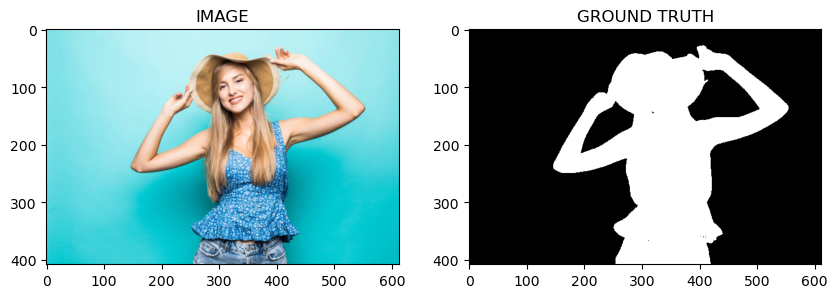

In [88]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

ax1.set_title('IMAGE')
ax1.imshow(image)

ax2.set_title('GROUND TRUTH')
ax2.imshow(mask,cmap = 'gray')

In [89]:
train_df, valid_df = train_test_split(df, test_size=0.2, random_state=42)

In [90]:
!pip install albumentations

  Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.3-cp312-cp312-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.3 which is incompatible.


In [91]:
!pip install --user albumentations

In [92]:
import sys
!{sys.executable} -m pip install albumentations

In [93]:
import albumentations as A

In [94]:
import albumentations

In [95]:
def get_train_augs():
  return albumentations.Compose([
      albumentations.Resize(IMAGE_SIZE, IMAGE_SIZE),
      albumentations.HorizontalFlip(p=0.5),
      albumentations.VerticalFlip(p=0.5)
  ],is_check_shapes=False)

def get_valid_augs():
    return albumentations.Compose([
        albumentations.Resize(IMAGE_SIZE, IMAGE_SIZE)
    ], is_check_shapes=False)

In [96]:
from torch.utils.data import Dataset

In [97]:
class SegmentationDataset(Dataset):
  def __init__(self, df, augmentations):
    self.df = df
    self.augmentations = augmentations

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    image_path = row.images
    mask_path = row.masks

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = np.expand_dims(mask, axis=-1)

    if self.augmentations:
      data = self.augmentations(image=image, mask=mask)
      image = data['image']
      mask = data['mask']
      image = np.transpose(image, (2, 0, 1)).astype(np.float32)
      mask = np.transpose(mask, (2, 0, 1)).astype(np.float32)

      image = torch.Tensor(image)
      mask = torch.Tensor(mask)

      return image, mask



In [98]:
trainset = SegmentationDataset(train_df, get_train_augs())
validset = SegmentationDataset(valid_df, get_valid_augs())

In [99]:
print(f"Size of Trainset : {len(trainset)}")
print(f"Size of Validset : {len(validset)}")

Size of Trainset : 232
Size of Validset : 58


In [100]:
pip install "numpy<2.0"

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..194.0].


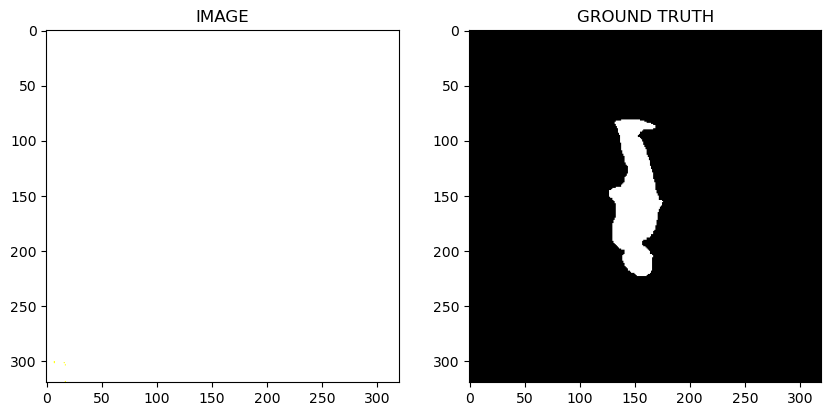

In [101]:
idx = 5
image, mask = trainset[idx]
helper.show_image(image, mask)

Task 5 : Load dataset into batches


In [102]:
from torch.utils.data import DataLoader

In [103]:
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
validloader = DataLoader(validset, batch_size=BATCH_SIZE)

In [104]:
print(f"Total number of batches in trainloader : {len(trainloader)}")
print(f"Total number of batches in validloader : {len(validloader)}")

Total number of batches in trainloader : 15
Total number of batches in validloader : 4


In [105]:
for image, mask in trainloader:
  print(f"Image batch shape : {image.shape}")
  print(f"Mask batch shape : {mask.shape}")
  break

Image batch shape : torch.Size([16, 3, 320, 320])
Mask batch shape : torch.Size([16, 1, 320, 320])


Task 6 : Create Segmentation Model


segmentation_models_pytorch documentation : https://smp.readthedocs.io/en/latest/

In [106]:
from torch import nn
import segmentation_models_pytorch as smp
from segmentation_models_pytorch.losses import DiceLoss

In [107]:
class SegmentationModel(nn.Module):
  def __init__(self):
    super(SegmentationModel, self).__init__()

    self.arc = smp.Unet(
        encoder_name=ENCODER,
        encoder_weights=WEIGHTS,
        in_channels=3,
        classes=1,
        activation=None
    )

  def forward(self, images, masks=None):
    logits = self.arc(images)
    if masks != None:
      loss1 = DiceLoss(mode='binary')(logits, masks)
      loss2 = nn.BCEWithLogitsLoss()(logits, masks)
      return logits, loss1 + loss2
    return logits

In [108]:
Device = "cpu"
model = SegmentationModel()
model.to(Device)

SegmentationModel(
  (arc): Unet(
    (encoder): EfficientNetEncoder(
      (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNormAct2d(
        32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        (act): Swish()
      )
      (blocks): Sequential(
        (0): Sequential(
          (0): DepthwiseSeparableConv(
            (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (bn1): BatchNormAct2d(
              32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
              (drop): Identity()
              (act): Swish()
            )
            (aa): Identity()
            (se): SqueezeExcite(
              (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (act1): Swish()
              (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
      

Task 7 : Create Train and Validation Function

In [109]:
def train_fn(data_loader, model, optimizer):
  model.train()
  total_loss = 0

  for images, masks in tqdm(data_loader):
    images = images.to(Device)
    masks = masks.to(Device)

    optimizer.zero_grad()
    logits, loss = model(images, masks)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
  return total_loss / len(data_loader)

In [110]:
def eval_fn(data_loader, model):
  model.eval()
  total_loss = 0
  with torch.no_grad():
    for images, masks in tqdm(data_loader):
      images = images.to(Device)
      masks = masks.to(Device)

      logits, loss = model(images, masks)
      total_loss += loss.item()
  return total_loss / len(data_loader)

Task 8 : Train Model

In [111]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [ ]:
best_valid_loss = np.inf
for epoch in range(EPOCHS):
  train_loss = train_fn(trainloader, model, optimizer)
  valid_loss = eval_fn(validloader, model)
  if valid_loss < best_valid_loss:
    torch.save(model.state_dict(), 'best_model.pt')
    print("Saved Best Model!")
  print(f"Epoch : {epoch+1}")
  print(f"Train Loss : {train_loss}")
  print(f"Valid Loss : {valid_loss}")

100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:14<00:00,  3.62s/it]


Saved Best Model!
Epoch : 1
Train Loss : -412.0636901855469
Valid Loss : -9472.570434570312


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:13<00:00,  3.33s/it]


Saved Best Model!
Epoch : 2
Train Loss : -1128.2592244466146
Valid Loss : -2820.540985107422


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:13<00:00,  3.31s/it]


...

100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:13<00:00,  3.37s/it]


Saved Best Model!
Epoch : 12
Train Loss : -19722.89609375
Valid Loss : -21161.712646484375


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:13<00:00,  3.48s/it]


Saved Best Model!
Epoch : 13
Train Loss : -22955.42109375
Valid Loss : -37867.47607421875


 13%|███████████                                                                        | 2/15 [00:35<03:55, 18.12s/it]

Task 9 : Inference

In [ ]:
idx = 8
model.load_state_dict(torch.load('best_model.pt'))
image, mask = validset[idx]
logits_mask = model(image.to(Device).unsqueeze(0))

In [ ]:
helper.show_image(image, mask, logits_mask)